In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.sparse import diags, eye
from scipy.sparse.linalg import splu

plt.rcParams["font.family"] = "Noto Sans CJK JP"


# 時間依存シュレーディンガー方程式の数値解法

1次元の単一粒子について
\[
i\hbar\partial_t\psi(x,t)
=\left[-\frac{\hbar^2}{2m}\partial_x^2+V(x)\right]\psi(x,t)
\]
を解く。以下では原子単位系 \(\hbar=m_e=e=a_0=E_h=1\) を使う。
位置はBohr半径 \(a_0\)、エネルギーはHartree \(E_h\)、時間は
\(\hbar/E_h\)（約 \(2.42\times10^{-17}\) s）で測る。

## Crank--Nicolson法

空間差分で得たHermite行列 \(H\) に対して
\[
\left(I+i\frac{\Delta t}{2}H\right)\Psi^{n+1}
=\left(I-i\frac{\Delta t}{2}H\right)\Psi^n.
\]
時間に依存しないHermiteな \(H\) では更新はユニタリであり、
離散確率 \(\Delta x\sum_j|\psi_j|^2\) を保存する。

## 空間差分と境界

\(-L/2<x<L/2\) を等間隔に分け、端点で \(\psi=0\) とする。
端点は固定したまま、内部点だけで離散Hamiltonianを作って時間発展させる。
有限領域のDirichlet境界は反射壁なので、波束が端まで届く前に散乱を観察する。

## 初期波束と障壁

正規化したガウス波束を
\[
\psi(x,0)=\frac{1}{(\pi\sigma^2)^{1/4}}
\exp\!\left[-\frac{(x-x_0)^2}{2\sigma^2}
+ik_0(x-x_0)\right]
\]
とする。自由粒子の平均運動量は \(k_0\)。波数 \(k_0\) に対応する運動エネルギーの中心値は
\(k_0^2/2\) Hartree。障壁に当たると波束は反射波と透過波に分かれる。
確率密度は \(|\psi(x,t)|^2\)、反射・透過確率は散乱後に
\(x<0\)、\(x>0\) でそれぞれ積分して求める。


In [2]:
def gaussian_wavepacket(x, x0, k0, sigma):
    envelope = (np.pi * sigma**2) ** (-0.25)
    return envelope * np.exp(
        -(x - x0)**2 / (2 * sigma**2) + 1j * k0 * (x - x0)
    )

def schrodinger_crank_nicolson(psi0, potential, x, dt, nsteps):
    dx = x[1] - x[0]
    size = len(x) - 2
    diagonal = 1 / dx**2 + potential[1:-1]
    off = np.full(size - 1, -0.5 / dx**2)
    hamiltonian = diags([off, diagonal, off], [-1, 0, 1], format="csc")
    identity = eye(size, format="csc")
    left = identity + 0.5j * dt * hamiltonian
    right = identity - 0.5j * dt * hamiltonian
    factor = splu(left)

    psi_t = np.zeros((nsteps + 1, len(x)), dtype=complex)
    psi_t[0, 1:-1] = psi0[1:-1]
    for n in range(nsteps):
        psi_t[n + 1, 1:-1] = factor.solve(right @ psi_t[n, 1:-1])
    return psi_t

# 原子単位系。端点は固定端、障壁は原点を中心とする。
length, points = 80.0, 3200
x = np.linspace(-length / 2, length / 2, points + 1)
dx = x[1] - x[0]
x0, sigma, k0 = -10.0, 1.8, 10.0
barrier_height, barrier_width = 36.2, 0.5
potential = np.zeros_like(x)
potential[np.abs(x) <= barrier_width / 2] = barrier_height

psi0 = gaussian_wavepacket(x, x0, k0, sigma)
psi0[[0, -1]] = 0.0
psi0 /= np.sqrt(np.trapezoid(np.abs(psi0)**2, x))

dt, final_time = 0.004, 2.8
nsteps = round(final_time / dt)
psi_t = schrodinger_crank_nicolson(psi0, potential, x, dt, nsteps)
times = np.arange(nsteps + 1) * dt
norms = np.trapezoid(np.abs(psi_t)**2, x, axis=1)
density = np.abs(psi_t[-1])**2
reflection = np.trapezoid(density[x < 0], x[x < 0])
transmission = np.trapezoid(density[x > 0], x[x > 0])
inside = np.abs(x) <= barrier_width / 2
barrier_probability = np.trapezoid(density[inside], x[inside])

assert np.isfinite(psi_t).all()
assert np.all(psi_t[:, [0, -1]] == 0.0)
assert abs(norms[0] - 1.0) < 1e-12
assert np.max(np.abs(norms - 1.0)) < 1e-10
assert abs(reflection + transmission - norms[-1]) < 1e-5
assert barrier_probability < 1e-8
print(f"norm drift: {np.max(np.abs(norms - 1.0)):.2e}")
print(f"at t={final_time:g} a.u.: P_R={reflection:.6f}, P_T={transmission:.6f}, P_barrier={barrier_probability:.2e}")


norm drift: 1.70e-13
at t=2.8 a.u.: P_R=0.133070, P_T=0.866930, P_barrier=3.23e-15


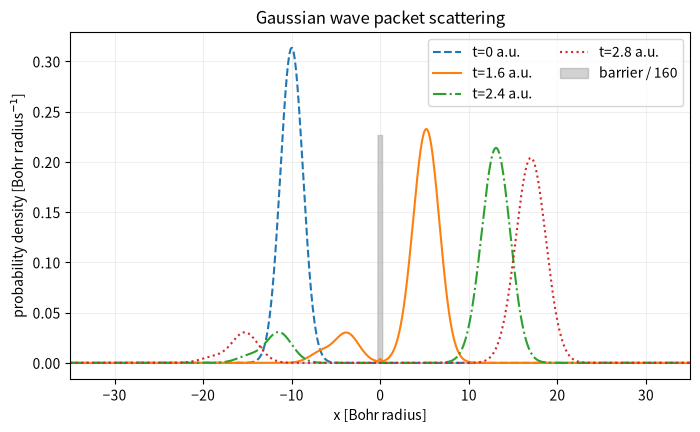

In [3]:
# 確率密度の時間発展
fig, ax = plt.subplots(figsize=(8, 4.5))
for t, style in zip((0.0, 1.6, 2.4, 2.8), ("--", "-", "-.", ":")):
    index = round(t / dt)
    ax.plot(x, np.abs(psi_t[index])**2, linestyle=style, label=f"t={t:g} a.u.")
ax.fill_between(
    x, 0, potential / 160, color="gray", alpha=0.35,
    label="barrier / 160"
)
ax.set(
    xlim=(-35, 35),
    xlabel="x [Bohr radius]",
    ylabel="probability density [Bohr radius$^{-1}$]",
    title="Gaussian wave packet scattering",
)
ax.legend(ncol=2)
ax.grid(alpha=0.2)
plt.show()

# 80コマのGIF。波束が有限領域の端に届く前までを保存する。
frames = np.linspace(0, nsteps, 81, dtype=int)
fig, ax = plt.subplots(figsize=(8, 4.5))
line, = ax.plot(x, np.abs(psi_t[0])**2)
ax.fill_between(x, 0, potential / 160, color="gray", alpha=0.35)
ax.set(xlim=(-35, 35), ylim=(0, 0.36), xlabel="x [Bohr radius]",
       ylabel="probability density [Bohr radius$^{-1}$]")

def update(frame):
    index = frames[frame]
    line.set_ydata(np.abs(psi_t[index])**2)
    ax.set_title(f"t={times[index]:.3f} a.u.")
    return (line,)

ani = FuncAnimation(fig, update, frames=len(frames), interval=80, blit=True)
ani.save("gauss_barrier_scattering.gif", writer="pillow", fps=12)
plt.close(fig)


## 実習：ポテンシャルを変える

障壁の高さ、幅または形状を変え、反射確率と透過確率の変化を比較する。
端点までの距離や計算終了時刻も変え、境界反射が散乱結果に混ざらないか確認する。
